In [2]:
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
df_clients = pd.read_csv('../data/clients.csv')
df_products = pd.read_csv('../data/products.csv')

# Data cleaning

## Clients

In [4]:
df_clients

,client_id,first_issue_date,first_redeem_date,age,gender
0,000012768d,2017-08-05 15:40:48,2018-01-04 19:30:07,45,U
1,000036f903,2017-04-10 13:54:23,2017-04-23 12:37:56,72,F
2,000048b7a6,2018-12-15 13:33:11,NaN,68,F
3,000073194a,2017-05-23 12:56:14,2017-11-24 11:18:01,60,F
4,00007c7133,2017-05-22 16:17:08,2018-12-31 17:17:33,67,U
...,...,...,...,...,...
400157,fffece623e,2018-05-13 15:09:30,2018-12-27 19:06:39,67,U
400158,ffff3dfff8,2018-11-01 16:06:52,2018-12-07 17:33:47,56,F
400159,ffffaab9da,2017-08-25 18:43:24,2017-12-08 17:53:19,23,F
400160,ffffeb5619,2017-12-05 13:26:28,NaN,62,U


In [5]:
for column in df_clients.columns:
    print(f'Число пропусков по колонке {column}: ', df_clients[column].isna().sum())

Число пропусков по колонке client_id:  0
Число пропусков по колонке first_issue_date:  0
Число пропусков по колонке first_redeem_date:  35469
Число пропусков по колонке age:  0
Число пропусков по колонке gender:  0


Пропуски только в колонке first_redeem_date (использование купона). Скорее всего у тех, кто купоном не воспользовался

### ID

In [5]:
df_clients['client_id'].value_counts()

client_id
000012768d    1
000036f903    1
000048b7a6    1
000073194a    1
00007c7133    1
             ..
fffece623e    1
ffff3dfff8    1
ffffaab9da    1
ffffeb5619    1
fffff6ce77    1
Name: count, Length: 400162, dtype: int64

Дубликаты по клиентам отсутсвуют

### Date

#### First_issue_date

In [6]:
df_clients['first_issue_date'].value_counts()

first_issue_date
2017-08-04 19:37:41    3
2017-08-09 18:57:54    3
2017-07-27 17:50:54    3
2017-10-04 10:25:38    3
2017-07-27 11:13:31    3
                      ..
2018-05-13 15:09:30    1
2018-11-01 16:06:52    1
2017-08-25 18:43:24    1
2017-12-05 13:26:28    1
2017-08-03 20:25:12    1
Name: count, Length: 396725, dtype: int64

In [7]:
(df_clients['first_issue_date'].min(), df_clients['first_issue_date'].max())

('2017-04-04 18:24:18', '2019-03-15 21:50:56')

In [8]:
df_clients[df_clients['first_issue_date'] == '2017-08-04 19:37:41']

,client_id,first_issue_date,first_redeem_date,age,gender
2903,01e65cc96d,2017-08-04 19:37:41,2017-11-16 17:38:19,58,U
165727,6a5a855a94,2017-08-04 19:37:41,2019-04-27 13:40:26,37,U
177368,71d2add4d2,2017-08-04 19:37:41,2018-12-29 18:12:13,34,U


#### First_redeem_date

In [9]:
df_clients['first_redeem_date'].value_counts()

first_redeem_date
2017-10-21 17:17:35    3
2018-12-29 19:07:00    3
2018-12-22 15:44:47    3
2019-02-01 20:54:59    3
2018-10-18 13:17:50    3
                      ..
2017-10-13 10:59:14    1
2018-12-27 19:06:39    1
2018-12-07 17:33:47    1
2017-12-08 17:53:19    1
2017-08-26 16:41:41    1
Name: count, Length: 362527, dtype: int64

In [10]:
(df_clients['first_redeem_date'].min(), df_clients['first_redeem_date'].max())

('2017-04-11 09:42:20', '2019-11-20 01:14:10')

In [11]:
df_clients[df_clients['first_redeem_date'] == '2017-10-21 17:17:35']

,client_id,first_issue_date,first_redeem_date,age,gender
24244,0f8ad6a269,2017-06-04 14:09:22,2017-10-21 17:17:35,65,U
119082,4c866aef27,2017-08-16 17:43:31,2017-10-21 17:17:35,59,F
371300,eda4fe436b,2017-09-15 19:24:55,2017-10-21 17:17:35,62,U


### Gender

In [12]:
df_clients['gender'].value_counts()

gender
U    185706
F    147649
M     66807
Name: count, dtype: int64

Около 50% пропусков по признаку "пол"

### Age

In [13]:
df_clients = df_clients[df_clients['age'].between(10, 90)]
df = df_clients.copy()

In [14]:
df['client_id'].count()

np.int64(398668)

In [15]:
def get_age_bar(df):
    df['age'] = pd.to_numeric(df['age'], errors='coerce')

    ages = df['age']
    
    plt.figure(figsize=(10, 6))
    plt.hist(ages, bins=20, edgecolor='black')
    plt.title('Распределение возрастов')
    plt.xlabel('Возраст')
    plt.ylabel('Кол-во')
    plt.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.show()


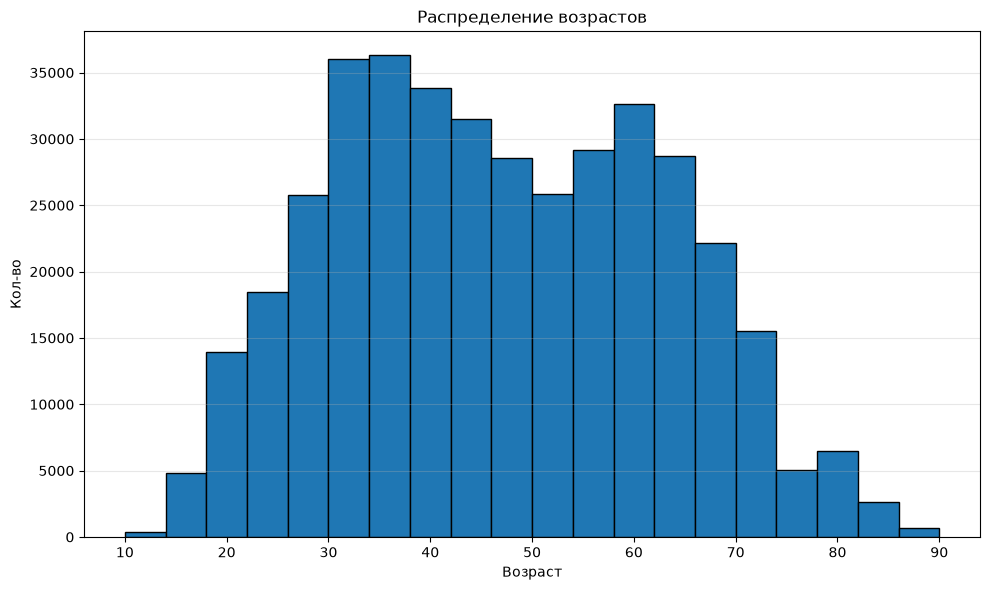

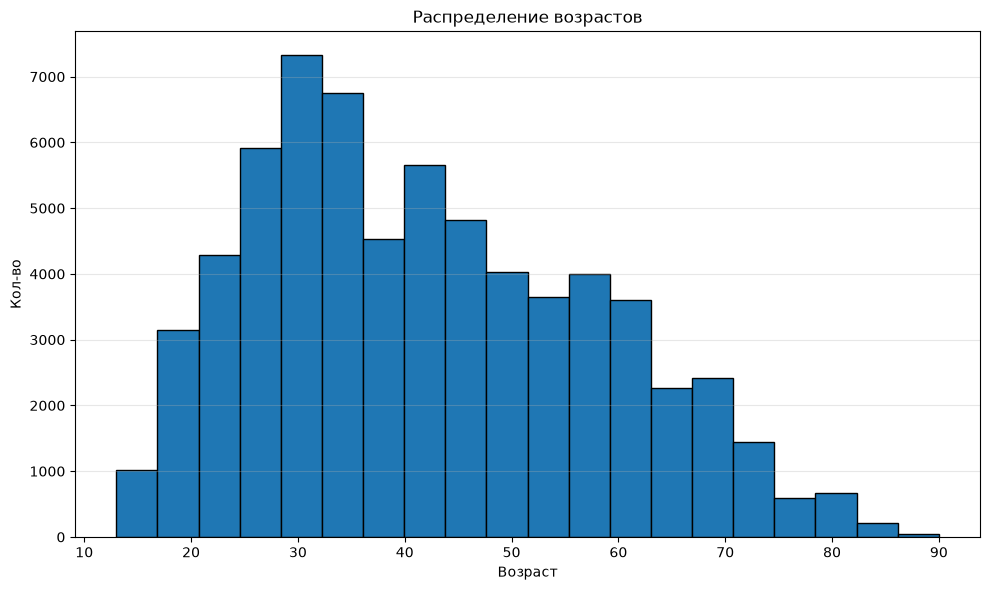

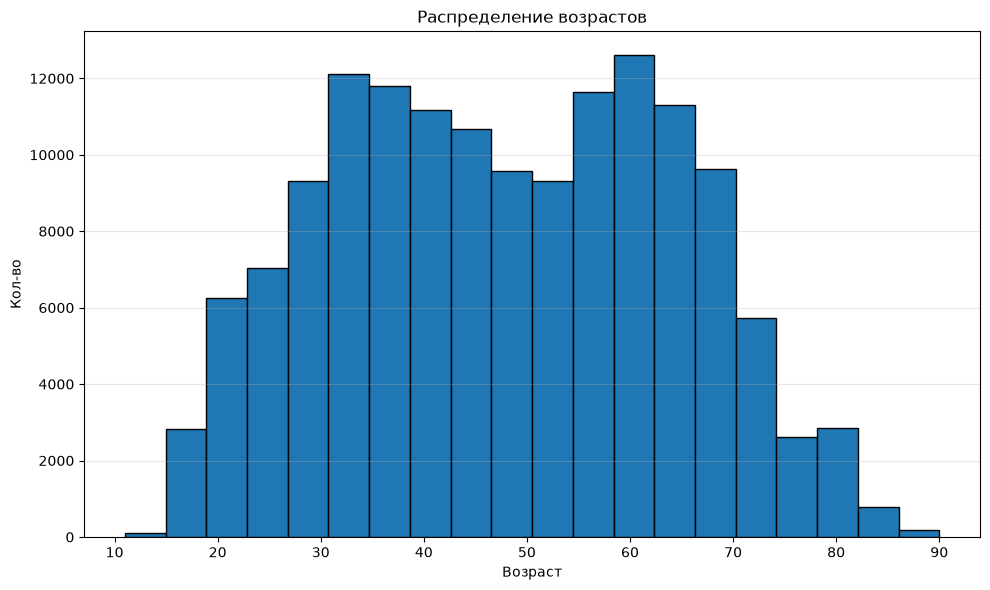

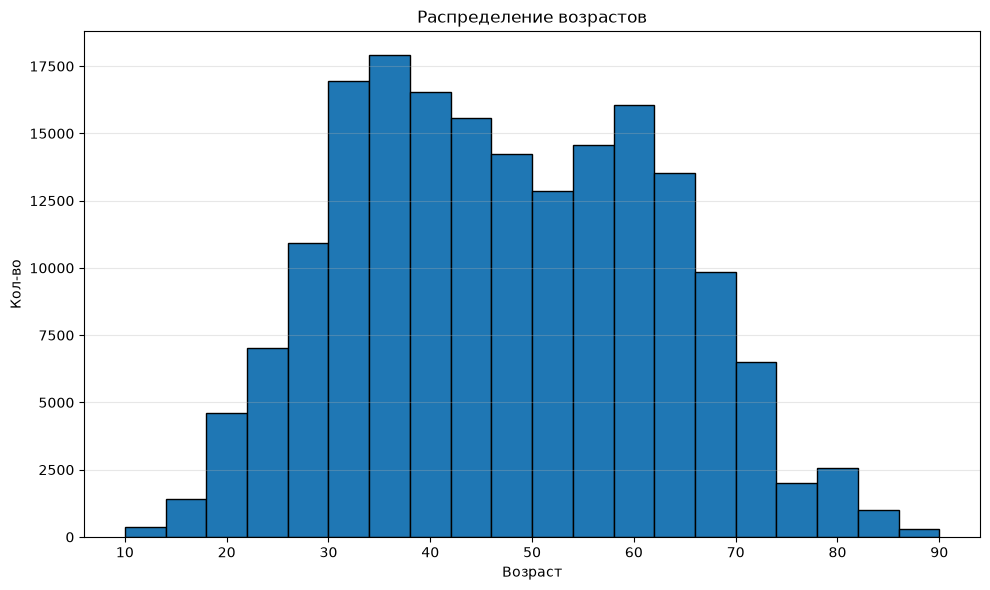

In [16]:
df_m = df[df['gender'] == 'M']
df_w = df[df['gender'] == 'F']
df_u = df[df['gender'] == 'U']

get_age_bar(df)
get_age_bar(df_m)
get_age_bar(df_w)
get_age_bar(df_u)

### Вывод

За исключением колонки Age, Gender вмешательства и отчистка не требуется.

Для Age на первом этапе применяем тривиальное удаление исходя из EDA.

Для Gender сделаем OHE на первом этапе. В дальнейшем построим модель/алгоритм, которые смогут восстановить пропуски

## Products

In [17]:
df_products

,product_id,level_1,level_2,level_3,level_4,segment_id,brand_id,vendor_id,netto,is_own_trademark,is_alcohol
0,0003020d3c,c3d3a8e8c6,c2a3ea8d5e,b7cda0ec0c,6376f2a852,123.0,394a54a7c1,9eaff48661,0.400,0,0
1,0003870676,e344ab2e71,52f13dac0c,d3cfe81323,6dc544533f,105.0,acd3dd483f,10486c3cf0,0.680,0,0
2,0003ceaf69,c3d3a8e8c6,f2333c90fb,419bc5b424,f6148afbc0,271.0,f597581079,764e660dda,0.500,0,0
3,000701e093,ec62ce61e3,4202626fcb,88a515c084,48cf3d488f,172.0,54a90fe769,03c2d70bad,0.112,0,0
4,0007149564,e344ab2e71,52f13dac0c,d3cfe81323,6dc544533f,105.0,63417fe1f3,f329130198,0.600,0,0
...,...,...,...,...,...,...,...,...,...,...,...
43033,fffac3a287,e344ab2e71,52f13dac0c,0f84eb7480,420c3b3f0b,150.0,5aef526287,f546d8aa6f,0.085,0,0
43034,fffd2946cf,e344ab2e71,52f13dac0c,a1786084ca,b2960bceb8,176.0,7bf16d4aa4,3d8c5ef5f4,0.130,0,0
43035,fffd7fb409,e344ab2e71,1d2939ba1d,2721c4b3d6,32f03574dd,255.0,1267326e16,0cfa052441,0.450,0,0
43036,fffd963a2c,c3d3a8e8c6,c2a3ea8d5e,a6b0dd76e0,a7e8f1cc02,220.0,c2eec3be6f,75ea3d1182,0.300,0,0


In [18]:
for column in df_products.columns:
    print(f'Число пропусков по колонке {column}: ', df_products[column].isna().sum())

Число пропусков по колонке product_id:  0
Число пропусков по колонке level_1:  3
Число пропусков по колонке level_2:  3
Число пропусков по колонке level_3:  3
Число пропусков по колонке level_4:  3
Число пропусков по колонке segment_id:  1572
Число пропусков по колонке brand_id:  5200
Число пропусков по колонке vendor_id:  34
Число пропусков по колонке netto:  3
Число пропусков по колонке is_own_trademark:  0
Число пропусков по колонке is_alcohol:  0


### Id

In [19]:
df_products['product_id'].value_counts()

product_id
0003020d3c    1
0003870676    1
0003ceaf69    1
000701e093    1
0007149564    1
             ..
fffac3a287    1
fffd2946cf    1
fffd7fb409    1
fffd963a2c    1
fffd992186    1
Name: count, Length: 43038, dtype: int64

Дубликаты и пропуски отсутсвуют

### Levels

In [20]:
df_products[df_products['level_1'].isna()]

,product_id,level_1,level_2,level_3,level_4,segment_id,brand_id,vendor_id,netto,is_own_trademark,is_alcohol
796,04d86b4b50,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0
12219,48cc0e256d,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0
17818,6a3d708544,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0


In [21]:
df_products = df_products[~df_products['level_1'].isna()]

### Segment & Brand & Vendor

In [22]:
df_products[df_products['brand_id'].isna()]

,product_id,level_1,level_2,level_3,level_4,segment_id,brand_id,vendor_id,netto,is_own_trademark,is_alcohol
6,0009170c33,c3d3a8e8c6,ad2b2e17d2,ca69ed9de2,8bbeabc581,212.0,NaN,6a48b9976d,0.400,0,0
12,00146e3ac6,e344ab2e71,52f13dac0c,0f84eb7480,420c3b3f0b,150.0,NaN,2445b69be2,0.070,0,0
35,002f491a94,c3d3a8e8c6,ad2b2e17d2,e33cc0b2a4,5330a84194,1.0,NaN,e5fdf61871,0.930,0,0
36,0031bd9d04,e344ab2e71,14d373dff5,ae662a854c,17a11d08ec,132.0,NaN,17a2c3b833,0.450,0,0
37,003234102a,c3d3a8e8c6,ad2b2e17d2,e33cc0b2a4,5330a84194,1.0,NaN,ddae13eb7a,0.900,0,0
...,...,...,...,...,...,...,...,...,...,...,...
43014,ffdc45ae88,e344ab2e71,52f13dac0c,0f84eb7480,420c3b3f0b,150.0,NaN,1304350254,0.180,0,0
43018,ffe30fd6b7,c3d3a8e8c6,de6f3b925a,68b1fb172a,9b5cb21dca,NaN,NaN,f9bbe26657,0.200,0,0
43020,ffe52e5ac8,e344ab2e71,52f13dac0c,3a80a917a4,98cdc326b3,110.0,NaN,8d7daaea9f,0.300,0,0
43023,ffe7aa49f5,ec62ce61e3,e8705574ff,4ea774ea51,5835d8be85,35.0,NaN,41aa9501e1,0.018,0,0


In [23]:
df_products[df_products['segment_id'].isna()]

,product_id,level_1,level_2,level_3,level_4,segment_id,brand_id,vendor_id,netto,is_own_trademark,is_alcohol
59,0058bda372,c3d3a8e8c6,de6f3b925a,68b1fb172a,741983ea3d,NaN,NaN,91ed29803e,0.250,0,0
69,00678eb1df,ec62ce61e3,a49a930a49,d1dc20357f,e83e5f0a95,NaN,NaN,01f7c589b1,0.038,0,0
121,00c8c8e837,c3d3a8e8c6,de6f3b925a,68b1fb172a,741983ea3d,NaN,8281de6bcb,6bc8b3c476,0.200,0,0
133,00de7e4339,ec62ce61e3,6b4ae3f25d,83f17acdfd,45e2127ec0,NaN,585124a4e4,6afe337e49,0.111,0,0
163,0116989c2c,c3d3a8e8c6,428e08386e,4797d587da,d39dc1f4bd,NaN,NaN,52a0b79928,0.100,0,0
...,...,...,...,...,...,...,...,...,...,...,...
42934,ff4c77d9d5,ec62ce61e3,6b4ae3f25d,83f17acdfd,0310d7e231,NaN,0d6f137fb6,01ea898857,0.192,0,0
42959,ff79a66f06,ec62ce61e3,6b4ae3f25d,a5b820d60d,82d29ef746,NaN,0d6f137fb6,afbf4c8d34,0.100,0,0
42975,ff9b10bb99,c3d3a8e8c6,91fb12a54a,f67fc26a36,a39c4edd69,NaN,4da2dc345f,25d82db007,1.000,0,0
43006,ffcb44ca47,e344ab2e71,52f13dac0c,38816369ce,27563baed9,NaN,2eecd3f5bf,61a6172002,0.300,0,0


In [24]:
df_products[df_products['vendor_id'].isna()]

,product_id,level_1,level_2,level_3,level_4,segment_id,brand_id,vendor_id,netto,is_own_trademark,is_alcohol
702,0455f05e64,e344ab2e71,703f4b6eb0,0d718a4e3b,130359c47f,259.0,3b48854ca9,NaN,0.140,0,0
1026,06453d1fa6,c3d3a8e8c6,ad2b2e17d2,ca69ed9de2,0736b62d31,157.0,4da2dc345f,NaN,0.200,0,0
1287,07b15f90c9,c3d3a8e8c6,fb84f08028,4603fa9fa5,f68966aaae,105.0,4da2dc345f,NaN,0.090,0,0
2517,0ee9c0b2d8,c3d3a8e8c6,428e08386e,e92017d246,cfd50afe18,105.0,4da2dc345f,NaN,0.115,0,0
3195,12da0599cf,c3d3a8e8c6,ad2b2e17d2,ca69ed9de2,3d648097f6,85.0,4cbf4b50ea,NaN,0.500,0,0
4011,17afcd062b,e344ab2e71,14d373dff5,39532a0f6f,16341715da,92.0,7975b3d6f8,NaN,1.500,0,0
6627,271fe85179,e344ab2e71,52f13dac0c,3a80a917a4,98cdc326b3,110.0,4da2dc345f,NaN,0.400,0,0
6962,290901c4de,e344ab2e71,52f13dac0c,38816369ce,4d4b7e1f16,105.0,4da2dc345f,NaN,0.380,0,0
10913,40b4801936,e344ab2e71,14d373dff5,39532a0f6f,16341715da,92.0,82e314e982,NaN,1.500,0,0
11076,41a0bbd03a,c3d3a8e8c6,428e08386e,100f2b1263,f31c4d6779,150.0,4da2dc345f,NaN,0.090,0,0


### Вывод

Для уровней (levels_i) категорий - пропусков очень мало, сами строки пустые. Можем легко избавиться от них.

Для Segment & Brand & Vendor пропуски тоже не так категоричны.
Для начального пайплайна сравним два подхода - удаление, заполнение их артефактами/статистиками. В дальнейшем попробуем провести аналитику, попробуем восстанавливать исходя из других товаров